# Mental Health Clinical Trials: Machine Learning

A follow-up to `01_trials_pipeline.ipynb`. It reuses the clean tables in `data/clean/` and asks three questions with scikit-learn:

* **F. Checking the grouping rules:** Can a text classifier, trained on the rule-based condition groups, find condition names the rules handle wrongly?
* **G. Predicting which trials stop early:** Can registration details (phase, sponsor, conditions, treatments, countries) predict whether a trial is terminated rather than completed?
* **H. Topics in trial titles:** What treatment approaches appear in trial titles, and which grew between 2010–12 and 2023–25?

Run the cells in order after `01_trials_pipeline.ipynb`. It works in Colab (Google Drive) or locally from the project folder. Results refer to the download of 1 October 2026.

## Setup

In [1]:
import os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

try:                                   # Colab: use the project folder in Google Drive
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT = '/content/drive/MyDrive/mental-health-trials-pipeline'
except ImportError:                    # locally: run from the project folder
    PROJECT = '.'
for sub in ['results/ml', 'images/ml']:
    os.makedirs(f'{PROJECT}/{sub}', exist_ok=True)

# keep_default_na=False so the phase value "NA" (not applicable) isn't read as missing
read = lambda name: pd.read_csv(f'{PROJECT}/data/clean/{name}.csv', keep_default_na=False, na_values=[''])
trials, conditions, interventions, sites = (read(n) for n in ['trials', 'conditions', 'interventions', 'sites'])
SEED = 42
for n, df in [('trials', trials), ('conditions', conditions), ('interventions', interventions), ('sites', sites)]:
    print(f'{n:14s} {len(df):>7,} rows')

trials          18,357 rows
conditions      40,636 rows
interventions   32,628 rows
sites           20,028 rows


## F. Checking the grouping rules with a text classifier

The pipeline groups each listed condition with keyword rules (C2). Here a classifier learns those groups from the condition text alone, using word and character n-grams (TF-IDF) and logistic regression. Every prediction is made by a model that never saw that condition name (5-fold cross-validation).

The rules are the labels, so the model mostly copies them. The useful part is where it **disagrees**: either the model is wrong, or the rules miss a spelling, word order or synonym. Disagreements are listed with how many trials use that condition name, so the most consequential ones come first.

**F1.** One row per distinct condition name (case-insensitive), with the number of trials that list it.

In [2]:
conditions['key'] = conditions['condition'].str.lower().str.strip()
names = (conditions.groupby('key')
         .agg(condition=('condition', 'first'), rule_group=('condition_group', 'first'),
              n_trials=('nct_id', 'nunique'))
         .reset_index())
print(len(names), 'distinct condition names')
print(names['rule_group'].value_counts().to_string())

7531 distinct condition names
rule_group
Other                        6213
Depression                    369
Anxiety                       251
Schizophrenia & psychosis     221
Substance use                 197
Bipolar disorder               94
PTSD                           92
Eating disorders               70
OCD                            24


**F2.** Cross-validated predictions and agreement with the rules.

In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline, make_union

text_model = make_pipeline(
    make_union(TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True),                      # words
               TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), sublinear_tf=True)),  # spelling variants
    LogisticRegression(C=10, max_iter=3000, class_weight='balanced'))

cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
proba = cross_val_predict(text_model, names['key'], names['rule_group'], cv=cv, method='predict_proba')
classes = np.unique(names['rule_group'])
names['model_group'] = classes[proba.argmax(axis=1)]
names['model_prob'] = proba.max(axis=1).round(3)

report = classification_report(names['rule_group'], names['model_group'], digits=3, output_dict=True)
pd.DataFrame(report).T.round(3).to_csv(f'{PROJECT}/results/ml/F_condition_classifier_report.csv')
print(classification_report(names['rule_group'], names['model_group'], digits=3))

                           precision    recall  f1-score   support

                  Anxiety      0.927     0.960     0.943       251
         Bipolar disorder      1.000     0.968     0.984        94
               Depression      0.981     0.970     0.975       369
         Eating disorders      0.800     0.971     0.877        70
                      OCD      0.955     0.875     0.913        24
                    Other      0.996     0.987     0.992      6213
                     PTSD      0.899     0.967     0.932        92
Schizophrenia & psychosis      0.973     0.991     0.982       221
            Substance use      0.861     0.975     0.914       197

                 accuracy                          0.984      7531
                macro avg      0.932     0.963     0.946      7531
             weighted avg      0.985     0.984     0.985      7531



**F3.** Where the model and the rules disagree, most-used condition names first.

In [4]:
dis = (names[names['model_group'] != names['rule_group']]
       .sort_values(['n_trials', 'model_prob'], ascending=False)
       [['condition', 'n_trials', 'rule_group', 'model_group', 'model_prob']])
dis.to_csv(f'{PROJECT}/results/ml/F_condition_disagreements.csv', index=False)
print(f'{len(dis)} of {len(names)} names disagree ({dis.n_trials.sum()} trial listings)')
pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 60)
print(dis.head(40).to_string(index=False))

117 of 7531 names disagree (763 trial listings)
                        condition  n_trials       rule_group               model_group  model_prob
                   Dental Anxiety       167            Other                   Anxiety       0.995
             Preoperative Anxiety        60            Other                   Anxiety       0.926
                        Anhedonia        53       Depression                     Other       0.527
                    Kinesiophobia        50            Other                   Anxiety       0.776
               Procedural Anxiety        45            Other                   Anxiety       0.998
                              MDD        39       Depression                     Other       0.977
           Respiratory Depression        36            Other                Depression       0.918
                              OCD        25              OCD                     Other       0.889
                       Alcoholism        22    Substance use 

**F4.** Check the rule-order fix. On the first run, one disagreement ("Bipolar Affective Disorder, Currently Depressed": rules said Depression, model said Bipolar) revealed that Depression was checked before Bipolar disorder, so "Bipolar Depression" and similar names were counted as Depression. Bipolar disorder is now checked first; this should find no bipolar-named condition outside the Bipolar group.

In [5]:
bip = conditions[conditions['key'].str.contains(r'bipolar|bi-polar|manic')
                 & (conditions['condition_group'] != 'Bipolar disorder')]
print(bip.groupby(['condition', 'condition_group'])['nct_id'].nunique()
         .sort_values(ascending=False).head(10).to_string())
bip_ids = set(bip['nct_id'])
grouped_bipolar = set(conditions.loc[conditions['condition_group'] == 'Bipolar disorder', 'nct_id'])
print(f'\nTrials listing a bipolar-named condition outside the Bipolar group: {len(bip_ids)}; '
      f'of these, {len(bip_ids - grouped_bipolar)} have no other condition in the Bipolar group')

Series([], )

Trials listing a bipolar-named condition outside the Bipolar group: 0; of these, 0 have no other condition in the Bipolar group


### Findings: grouping rules

**First run, on the original rules** (disagreements saved in `results/ml/F_condition_disagreements_before_fix.csv`):

* The classifier agreed with the rules on 98.5% of 7,531 distinct condition names. The 116 disagreements (807 trial listings) were of three kinds:
  * **Deliberate exclusions working as intended:** dental anxiety (167 trials), preoperative and procedural anxiety, kinesiophobia, respiratory depression. The model can't see the exclusion list, so these confirm the exclusions rather than reveal errors.
  * **Model errors:** short acronyms and single words the rules already match (MDD, OCD, GAD, anhedonia, alcoholism) and everyday eating terms that aren't eating disorders (healthy eating, picky eating, time-restricted eating).
  * **Rule gaps:** wordings the rules missed because of word order, punctuation or synonyms, for example "Stress Disorders, Traumatic", "Alcohol-Related Disorders", "Drug Abuse", "Eating, Binge", "Avoidant / Restrictive Food Intake Disorder" and "Bi-Polar Disorder".
* **Rule order:** one low-frequency disagreement revealed that Depression was checked before Bipolar disorder, so "Bipolar Depression" (118 trials) and similar names were counted as Depression; 139 trials had no other condition in the Bipolar group.

**Fixes applied in `01_trials_pipeline.ipynb` (C2):** Bipolar disorder is now checked first, and the PTSD, substance use, eating disorder and bipolar patterns cover the missed wordings. 286 condition rows changed group; the analysis set grew from 14,713 to 14,724 trials, and the Bipolar group from 783 to 965 condition rows. Headline results barely moved (bipolar growth ×1.17 → ×1.20), but bipolar disorder now has the highest Canadian share (9.4%).

**After the fixes** (this run): agreement is 98.4% and F4 finds no bipolar-named condition outside the Bipolar group. The 117 remaining disagreements are exclusions, model errors and scope decisions left as they are on purpose: tobacco and nicotine use, "Alcohol Drinking" (a behaviour rather than a disorder), generic "Stress Disorder" and "Cannabis" (often the treatment being tested, e.g. cannabidiol). A few rare candidates remain (e.g. "Cannabis-Related Disorder", "Benzodiazepine Withdrawal", 2 trials each).

## G. Predicting which trials stop early

**Question:** Using only information known when a trial is registered, can we predict whether it will be **terminated** rather than **completed**?

* **Trials:** In-scope trials that are completed or terminated. Withdrawn trials (stopped before enrolling anyone) and suspended trials are left out, because their registry records are often incomplete.
* **Leakage check:** `enrollment` is excluded. For ended trials it is the *actual* number enrolled, which is much lower for terminated trials (median 17 vs 71), so it reveals the outcome rather than predicting it. G4 shows what happens if it is included.
* **Class imbalance:** Only about 8% of these trials were terminated, so accuracy is misleading (predicting "completed" for everyone scores 92%). Models are compared on ROC AUC and average precision, and logistic regression and gradient boosting use `class_weight='balanced'`.

**G1.** One row per trial with its features.

In [6]:
d = trials[(trials['in_scope'] == 1) & trials['overall_status'].isin(['COMPLETED', 'TERMINATED'])].copy()
d['terminated'] = (d['overall_status'] == 'TERMINATED').astype(int)

def flags(df, col, prefix):
    out = df.assign(v=1).pivot_table(index='nct_id', columns=col, values='v', aggfunc='max')
    out.columns = [prefix + re.sub(r'[^a-z]+', '_', str(c).lower()).strip('_') for c in out.columns]
    return out

cond_flags = flags(conditions[conditions['condition_group'] != 'Other'], 'condition_group', 'cond_')
int_flags = flags(interventions, 'intervention_type', 'int_')
cls = interventions.groupby('nct_id')['psychedelic_class']
counts = pd.DataFrame({
    'n_conditions': conditions.groupby('nct_id').size(),
    'n_interventions': interventions.groupby('nct_id').size(),
    'psychedelic': cls.apply(lambda x: (x == 'Psychedelic / MDMA').any()).astype(int),
    'ketamine': cls.apply(lambda x: (x == 'Ketamine / esketamine').any()).astype(int),
    'n_countries': sites.groupby('nct_id')['country'].nunique(),
    'us_site': sites.groupby('nct_id')['country'].apply(lambda x: (x == 'United States').any()).astype(int),
    'canada_site': sites.groupby('nct_id')['country'].apply(lambda x: (x == 'Canada').any()).astype(int),
})
d = d.set_index('nct_id').join(cond_flags).join(int_flags).join(counts)

CAT = ['phase', 'sponsor_class']
NUM = ['start_year', 'n_conditions', 'n_interventions', 'n_countries']
BIN = list(cond_flags.columns) + list(int_flags.columns) + ['psychedelic', 'ketamine', 'us_site', 'canada_site']
d[BIN] = d[BIN].fillna(0)
d['phase'] = d['phase'].fillna('NA')
X, y = d[CAT + NUM + BIN], d['terminated']
print(f'{len(d):,} trials; {y.sum()} terminated ({y.mean():.1%})')
print('Features:', len(CAT + NUM + BIN))

9,473 trials; 772 terminated (8.1%)
Features: 29


**G2.** Preprocessing inside a pipeline, so it is learned from training data only: one-hot encoding for phase and sponsor type (rare categories pooled), median imputation and scaling for counts, and binary flags passed through. The data are split 80/20 (stratified); each model is tuned with 5-fold cross-validation on the training set and scored once on the test set.

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import average_precision_score, balanced_accuracy_score, roc_auc_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def preprocess(num=NUM):
    return ColumnTransformer([
        ('cat', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=30), CAT),
        ('num', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), num),
        ('bin', 'passthrough', BIN)])

MODELS = {
    'Baseline (always "completed" rate)': (DummyClassifier(strategy='prior'), {}),
    'Logistic regression': (LogisticRegression(max_iter=3000, class_weight='balanced'),
                            {'model__C': [0.1, 1, 10]}),
    'Gradient boosting': (HistGradientBoostingClassifier(class_weight='balanced', learning_rate=0.05,
                                                          max_iter=200, random_state=SEED),
                          {'model__max_depth': [2, 3, None], 'model__min_samples_leaf': [20, 100]}),
    'Neural network (MLP)': (MLPClassifier(max_iter=400, random_state=SEED),
                             {'model__hidden_layer_sizes': [(16,), (32,)], 'model__alpha': [0.1, 1.0, 3.0]}),
}

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
fitted, rows = {}, []
for name, (model, grid) in MODELS.items():
    search = GridSearchCV(Pipeline([('prep', preprocess()), ('model', model)]), grid or {'model__strategy': ['prior']},
                          scoring='average_precision', cv=cv, n_jobs=-1).fit(X_tr, y_tr)
    est = fitted[name] = search.best_estimator_
    p = est.predict_proba(X_te)[:, 1]
    rows.append({'model': name, 'cv_average_precision': round(search.best_score_, 3),
                 'test_roc_auc': round(roc_auc_score(y_te, p), 3),
                 'test_average_precision': round(average_precision_score(y_te, p), 3),
                 'test_balanced_accuracy': round(balanced_accuracy_score(y_te, est.predict(X_te)), 3),
                 'best_settings': {k.replace('model__', ''): v for k, v in search.best_params_.items()}})
results = pd.DataFrame(rows)
results.to_csv(f'{PROJECT}/results/ml/G_stopped_early_models.csv', index=False)
print(results.drop(columns='best_settings').to_string(index=False))
print('\nBest settings:'); [print(' ', r.model, r.best_settings) for r in results.itertuples()]

                             model  cv_average_precision  test_roc_auc  test_average_precision  test_balanced_accuracy
Baseline (always "completed" rate)                 0.082         0.500                   0.081                   0.500
               Logistic regression                 0.162         0.651                   0.138                   0.616
                 Gradient boosting                 0.175         0.664                   0.139                   0.617
              Neural network (MLP)                 0.166         0.673                   0.145                   0.500

Best settings:
  Baseline (always "completed" rate) {'strategy': 'prior'}
  Logistic regression {'C': 0.1}
  Gradient boosting {'max_depth': 3, 'min_samples_leaf': 100}
  Neural network (MLP) {'alpha': 0.1, 'hidden_layer_sizes': (16,)}


[None, None, None, None]

**G3.** Test-set detail for the best model (chosen by cross-validated average precision on the training set, so the test set stays untouched): ROC curves for all models, the confusion matrix at the default threshold, and which features matter (permutation importance on the test set: the drop in average precision when a feature is shuffled).

Best model (cross-validated average precision on the training set): Gradient boosting
              precision    recall  f1-score   support

   Completed      0.944     0.708     0.809      1741
  Terminated      0.137     0.526     0.218       154

    accuracy                          0.693      1895
   macro avg      0.541     0.617     0.513      1895
weighted avg      0.878     0.693     0.761      1895



        feature  importance     sd
        us_site      0.0184 0.0068
       int_drug      0.0082 0.0042
 int_behavioral      0.0079 0.0045
          phase      0.0062 0.0037
   n_conditions      0.0029 0.0030
   cond_anxiety      0.0028 0.0015
    canada_site      0.0022 0.0035
     start_year      0.0017 0.0078
     int_device      0.0015 0.0030
n_interventions      0.0012 0.0008


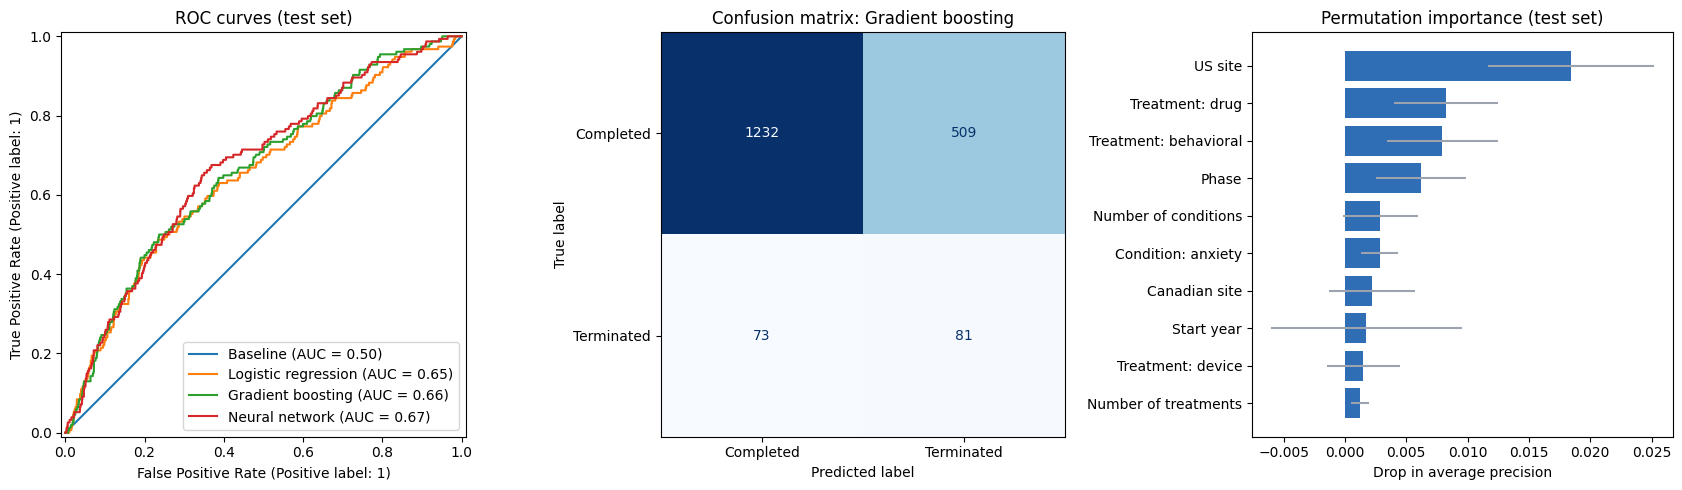

In [8]:
from sklearn.inspection import permutation_importance
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

best = results.iloc[1:].sort_values('cv_average_precision', ascending=False)['model'].iloc[0]   # chosen on training CV, not the test set
print('Best model (cross-validated average precision on the training set):', best)
print(classification_report(y_te, fitted[best].predict(X_te), target_names=['Completed', 'Terminated'], digits=3))

imp = permutation_importance(fitted[best], X_te, y_te, scoring='average_precision',
                             n_repeats=30, random_state=SEED, n_jobs=-1)
imp = (pd.DataFrame({'feature': X.columns, 'importance': imp.importances_mean, 'sd': imp.importances_std})
       .sort_values('importance', ascending=False))
imp.round(4).to_csv(f'{PROJECT}/results/ml/G_stopped_early_importance.csv', index=False)
print(imp.head(10).round(4).to_string(index=False))

fig, ax = plt.subplots(1, 3, figsize=(17, 5))
for name, est in fitted.items():
    RocCurveDisplay.from_estimator(est, X_te, y_te, ax=ax[0], name=name.split(' (')[0])
ax[0].set_title('ROC curves (test set)')
ConfusionMatrixDisplay.from_estimator(fitted[best], X_te, y_te, display_labels=['Completed', 'Terminated'],
                                      ax=ax[1], cmap='Blues', colorbar=False)
ax[1].set_title(f'Confusion matrix: {best}')
PRETTY = {'us_site': 'US site', 'canada_site': 'Canadian site', 'phase': 'Phase', 'sponsor_class': 'Sponsor type',
          'start_year': 'Start year', 'n_interventions': 'Number of treatments', 'n_conditions': 'Number of conditions',
          'n_countries': 'Number of countries', 'psychedelic': 'Psychedelic / MDMA', 'ketamine': 'Ketamine'}
pretty = lambda f: PRETTY.get(f, f.replace('int_', 'Treatment: ').replace('cond_', 'Condition: ').replace('_', ' '))
top = imp.head(10).iloc[::-1]
ax[2].barh(top['feature'].map(pretty), top['importance'], xerr=top['sd'], color='#2f6db5', ecolor='#9ca3af')
ax[2].set(title='Permutation importance (test set)', xlabel='Drop in average precision')
fig.tight_layout()
fig.savefig(f'{PROJECT}/images/ml/stopped_early.png', dpi=150, bbox_inches='tight')
plt.show()

**G4.** Leakage check: the same best model with `enrollment` added.

In [9]:
leaky = Pipeline([('prep', preprocess(NUM + ['enrollment'])), ('model', fitted[best].named_steps['model'])])
leaky.fit(d.loc[X_tr.index, CAT + NUM + BIN + ['enrollment']], y_tr)
p = leaky.predict_proba(d.loc[X_te.index, CAT + NUM + BIN + ['enrollment']])[:, 1]
print(f'With enrollment: test ROC AUC {roc_auc_score(y_te, p):.3f}, average precision {average_precision_score(y_te, p):.3f}')
print('Median enrollment:', d.groupby('terminated')['enrollment'].median().rename({0: 'completed', 1: 'terminated'}).to_dict())

With enrollment: test ROC AUC 0.809, average precision 0.391
Median enrollment: {'completed': 70.5, 'terminated': 17.0}


### Findings: predicting early stopping

* **Registration details predict early stopping only weakly.** On the test set, gradient boosting (chosen by cross-validation) reached a ROC AUC of 0.66 and average precision of 0.14, against 0.50 and 0.08 for the baseline. Logistic regression (0.65) and the neural network (0.67) were essentially tied, so the limit is the information available, not the algorithm.
* **At the default threshold** gradient boosting flagged 53% of terminated trials, but only 14% of the trials it flagged were actually terminated: useful for screening a shortlist, not for confident prediction. The neural network, which has no class weighting, predicted "completed" for every trial at the default threshold (balanced accuracy 0.50), even though it ranked trials about as well as the others.
* **What the model used:** A US site, drug treatments and later-phase designs went with more terminations (for example 14% of drug trials vs 6% of others; 16% of phase 2–4 trials vs 6% of trials with no phase), and behavioural treatments with fewer (5% vs 11%).
* **Caveat on the US effect:** Trials without a US site are far more often left with an "Unknown" status (23% vs 5% of trials started by 2020), so some of their terminations are probably never recorded. Part of the US effect is likely a reporting difference rather than a real one.
* **Leakage check:** Adding `enrollment` raised the test ROC AUC from 0.66 to 0.81, because for ended trials it is the actual number enrolled (median 17 terminated vs 71 completed). It reveals the outcome rather than predicting it, which is why it is excluded.

## H. Topics in trial titles

Topic modelling finds groups of words that tend to appear together, without any labels. Condition names (depression, PTSD, schizophrenia, …) are removed first, because the condition groups already cover them; what remains describes **how** conditions are being treated or studied. Non-negative matrix factorisation (NMF) on TF-IDF title features finds 16 topics; each trial is assigned its strongest topic, or none if no topic is clearly present.

**H1.** Fit the topics and list each topic's top words.

In [10]:
from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

GENERIC = '''study trial trials effect effects effectiveness efficacy safety randomized randomised controlled pilot
patients patient adults adult treatment treatments evaluation evaluate evaluating clinical versus vs use using based
comparison compare comparing feasibility phase impact people individuals participants subjects healthy volunteers
open label double blind placebo multicenter care intervention interventions program programme disorder disorders
symptoms improve improving reduce reducing group'''.split()
CONDITION_WORDS = '''depression depressive depressed major mdd anxiety social generalized schizophrenia schizoaffective
bipolar ptsd posttraumatic traumatic post stress ocd obsessive compulsive anorexia bulimia nervosa binge eating alcohol
opioid opioids cocaine cannabis substance methamphetamine dependence psychosis psychotic resistant veterans postpartum
children adolescents adolescent youth women older disease related illness severe mood mental health'''.split()

scope = trials[trials['in_scope'] == 1].copy()
vec = TfidfVectorizer(stop_words=list(ENGLISH_STOP_WORDS | set(GENERIC) | set(CONDITION_WORDS)),
                      ngram_range=(1, 2), min_df=5, max_df=0.3, sublinear_tf=True)
T = vec.fit_transform(scope['title'].fillna(''))
words = np.array(vec.get_feature_names_out())
nmf = NMF(n_components=16, init='nndsvda', random_state=SEED, max_iter=800)
W = nmf.fit_transform(T)

def label(comp, n=3):        # name each topic by its top single words
    out = []
    for w in words[comp.argsort()[::-1]]:
        if ' ' not in w and w not in out:
            out.append(w)
        if len(out) == n:
            break
    return ', '.join(out)

topics = pd.DataFrame({'topic': range(nmf.n_components),
                       'label': [label(c) for c in nmf.components_],
                       'top_words': [', '.join(words[c.argsort()[::-1][:10]]) for c in nmf.components_]})
topics.to_csv(f'{PROJECT}/results/ml/H_title_topics.csv', index=False)
print(topics[['topic', 'top_words']].to_string(index=False))

 topic                                                                                                                                                    top_words
     0 behavioral, cognitive, cognitive behavioral, behavioral therapy, therapy, activation, behavioral activation, remediation, cognitive remediation, therapy cbt
     1           magnetic, magnetic stimulation, transcranial magnetic, transcranial, stimulation, repetitive, repetitive transcranial, rtms, stimulation rtms, tms
     2                                  virtual, reality, virtual reality, exposure, reality exposure, reality glasses, glasses, exposure therapy, reality pain, vr
     3          therapy, exposure, exposure therapy, cognitive, acceptance, commitment, commitment therapy, acceptance commitment, cognitive therapy, music therapy
     4                              training, cognitive, cognitive training, attention, skills, control, remediation, metacognitive training, memory, metacognitive
     5          

**H2.** Each topic's share of trials in 2010–12 and 2023–25 (trials with no clear topic count in the denominator).

No clear topic: 45% of titles
                                             label  share_2010_12  share_2023_25  change_pts
topic                                                                                       
14                  adjunctive, tolerability, term          0.096          0.041      -5.590
0                   behavioral, cognitive, therapy          0.056          0.035      -2.181
1              magnetic, transcranial, stimulation          0.025          0.016      -0.950
11                        internet, cbt, delivered          0.032          0.023      -0.890
7      ketamine, electroconvulsive, antidepressant          0.015          0.012      -0.374
10                     exercise, physical, aerobic          0.022          0.024       0.192
4                   training, cognitive, attention          0.019          0.022       0.227
13                              life, early, sleep          0.072          0.078       0.519
6                         brain, stimula

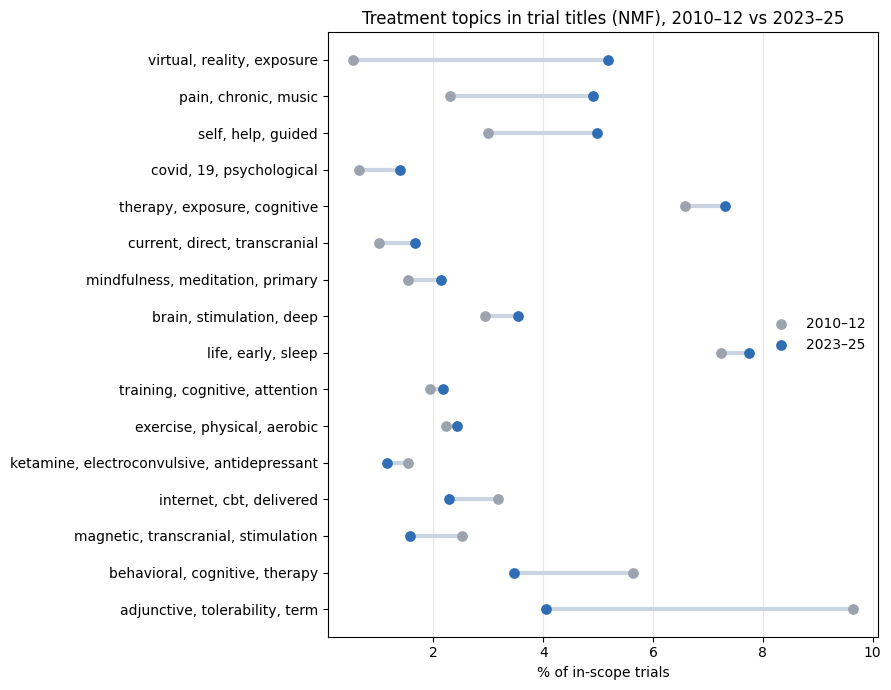

In [11]:
scope['topic'] = np.where(W.max(axis=1) >= 0.02, W.argmax(axis=1), -1)
share = lambda years: scope[scope['start_year'].between(*years)]['topic'].value_counts(normalize=True)
trend = (pd.DataFrame({'share_2010_12': share((2010, 2012)), 'share_2023_25': share((2023, 2025))})
         .drop(index=-1, errors='ignore').fillna(0).join(topics.set_index('topic')['label']))
trend['change_pts'] = (trend['share_2023_25'] - trend['share_2010_12']) * 100
trend = trend.sort_values('change_pts')
trend.round(4).to_csv(f'{PROJECT}/results/ml/H_topic_trends.csv')
print(f"No clear topic: {(scope['topic'] == -1).mean():.0%} of titles")
print(trend[['label', 'share_2010_12', 'share_2023_25', 'change_pts']].round(3).to_string())

fig, ax = plt.subplots(figsize=(9, 7))
yy = np.arange(len(trend))
ax.hlines(yy, trend['share_2010_12'] * 100, trend['share_2023_25'] * 100, color='#cbd5e1', lw=3)
ax.scatter(trend['share_2010_12'] * 100, yy, color='#9ca3af', s=45, label='2010–12', zorder=3)
ax.scatter(trend['share_2023_25'] * 100, yy, color='#2f6db5', s=45, label='2023–25', zorder=3)
ax.set_yticks(yy, trend['label'])
ax.set(xlabel='% of in-scope trials', title='Treatment topics in trial titles (NMF), 2010–12 vs 2023–25')
ax.legend(frameon=False, loc='center right')
ax.grid(axis='x', alpha=0.3)
fig.tight_layout()
fig.savefig(f'{PROJECT}/images/ml/title_topics.png', dpi=150, bbox_inches='tight')
plt.show()

### Findings: title topics

* **Virtual reality was the fastest-growing topic,** from 0.5% of trials in 2010–12 to 5.2% in 2023–25, consistent with the device growth in D3.
* **Pain and procedure-related anxiety** (pain, music, surgery) rose from 2.3% to 4.9%, and **guided self-help, online and mobile** approaches from 3.0% to 5.0%. Mindfulness and transcranial direct-current stimulation (tDCS) also grew slightly.
* **The biggest decline was drug-development language** (adjunctive, tolerability, long-term, pharmacokinetics): from 9.6% to 4.1%, matching the fall in drug and industry share in D3 and D4b. Classic cognitive behavioural therapy titles also fell (5.6% to 3.5%), while internet-delivered CBT stayed small.
* **Psychedelics did not form their own topic.** With about 165 in-scope psychedelic trials among 14,724 titles, they are too few for NMF to separate; the keyword flag in C3 remains the better way to track them.
* 45% of titles had no clear topic, mostly short titles naming a drug or a condition only. Topic labels are the top three words of each topic, so they describe rather than define it, and small changes in the data can reshuffle the weaker topics.